# Jaipur Junction-Informed Railway Platform Allocation — Benchmark V5

## Purpose
V5 moves beyond the small 8–12 train pilot. It tests whether Exact Search, a classical greedy heuristic, OpenJij Simulated Annealing (SA), and OpenJij Simulated Quantum Annealing (SQA) behave differently as the synthetic railway scheduling problem grows from **8 to 28 trains**.

### What stays unchanged
- Six abstract platform resources.
- Four long-train-capable platforms in the primary benchmark.
- A train with 24 or more coaches can only use a long-train-capable platform.
- Two trains cannot occupy the same platform when their actual occupation intervals, including clearance, overlap.
- The objective is to minimise the number of trains moved from their nominal platform.
- Clearance is five minutes as an experimental assumption, not a verified Jaipur operating rule.

### What changes in V5
- Train counts: 8, 12, 16, 20, 24 and 28.
- Delay stress levels: 5, 15 and 30 minutes (maximum independently sampled delay; these are experimental levels, not reported Jaipur delay distributions).
- Three data seeds: 11, 22 and 33.
- Exact Search is attempted on every dataset with a strict time limit. A timeout is reported as **unknown**, never as infeasible or optimal.
- Greedy, SA and SQA are tested on the same generated data.
- A controlled four-versus-five long-platform sensitivity experiment reuses the same trains and times, changing only long-train platform eligibility.

## Important interpretation limits
This is a **Jaipur Junction-informed synthetic benchmark**, not a reconstruction of actual Jaipur train movements. Public historical aggregate statistics motivate the scale, but train-level schedules, platform assignments and delays are generated synthetically. No quantum hardware is used; OpenJij SQA is a classical simulation.

**Do not describe a timeout as an exact result. Do not claim quantum advantage from these experiments.** The objective is to obtain reproducible evidence about solution quality, feasibility and runtime across problem sizes.

## 0. Setup

Run this cell in the notebook kernel where you intend to run the experiment. If you install packages, restart the kernel when VS Code asks you to.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, itertools, math, json, os, random, importlib.metadata
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    RAM_GB = None

try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB if RAM_GB is not None else "not measured")
print("OpenJij:", OPENJIJ_VERSION)
try:
    import torch
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
except Exception:
    print("PyTorch/CUDA not installed. OpenJij SA/SQA calls in this notebook are CPU sampler calls.")

Python: 3.12.12
Platform: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2
PyTorch/CUDA not installed. OpenJij SA/SQA calls in this notebook are CPU sampler calls.


## 2. Experiment settings

The full V5 experiment is enabled by default. Its largest workload is 28 trains. Exact Search is time-limited per instance, while SA/SQA use the same reads, sweeps and independent repeats. You can reduce the settings for a quick test.

In [3]:
# Railway model assumptions
N_PLATFORMS = 6
PEAK_WINDOW_START = 12 * 60
PEAK_WINDOW_END = 18 * 60
BASE_CLEARANCE_MIN = 5                 # experimental assumption, not a verified Jaipur-specific rule
LONG_TRAIN_COACH_THRESHOLD = 24
LONG_PLATFORM_COUNT_MAIN = 4           # abstract primary-case eligibility assumption

# Main scaling design: 6 sizes x 3 delay levels x 3 seeds = 54 unique datasets
TRAIN_COUNTS = [8, 12, 16, 20, 24, 28]
DELAY_LEVELS_MIN = [5, 15, 30]
DATASET_SEEDS = [11, 22, 33]

# Solver settings
SOLVER_REPEATS = 2
NUM_READS = 100
NUM_SWEEPS = 1000
EXACT_TIME_LIMIT_S = 2.0               # per dataset; TIMEOUT is not an optimality proof
GREEDY_RESTARTS = 30

# Additional paired sensitivity experiments
RUN_CAPACITY_SENSITIVITY = True        # 28 trains, 15-minute delay, 4 vs 5 long-platform-capable platforms
RUN_EFFORT_SENSITIVITY = True          # one difficult 28-train instance, increased reads/sweeps
EFFORT_CONFIGS = [(100, 500), (200, 1000), (300, 2000)]
EFFORT_REPEATS = 2

# Guard against unintentionally launching a larger experiment
RUN_MAIN_BENCHMARK = True

EXPECTED_DATASETS = len(TRAIN_COUNTS) * len(DELAY_LEVELS_MIN) * len(DATASET_SEEDS)
print("Unique main datasets:", EXPECTED_DATASETS)
print("Main SA/SQA sampler calls:", EXPECTED_DATASETS * 2 * SOLVER_REPEATS)
print("Exact per-instance time limit:", EXACT_TIME_LIMIT_S, "seconds")
print("QUBO penalty rule: lambda = N + 1. This is sufficient to make any feasible assignment lower-energy than any infeasible bitstring, when a feasible assignment exists.")

Unique main datasets: 54
Main SA/SQA sampler calls: 216
Exact per-instance time limit: 2.0 seconds
QUBO penalty rule: lambda = N + 1. This is sufficient to make any feasible assignment lower-energy than any infeasible bitstring, when a feasible assignment exists.


## 3. Synthetic timetable generator and independent validator

Nominal assignments are created first with no same-platform overlap. Each train then receives an independently sampled delay, shifting its arrival and departure by the same amount (dwell time is preserved). Conflicts are computed from actual occupation intervals plus clearance.

The 18/97 long-train proportion is a historical aggregate used only to scale the synthetic long-train count. It is not an observed count for this six-hour window.

In [4]:
def scheduled_same_platform_conflicts(df: pd.DataFrame, clearance_min: int):
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].scheduled_arrival_min)
        ei = int(df.iloc[i].scheduled_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            if int(df.iloc[i].nominal_platform) != int(df.iloc[j].nominal_platform):
                continue
            sj = int(df.iloc[j].scheduled_arrival_min)
            ej = int(df.iloc[j].scheduled_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej): conflicts.append((i, j))
    return conflicts


def generate_jaipur_profile_instance(n_trains: int, seed: int, delay_max_min: int,
                                     long_platform_count: int = LONG_PLATFORM_COUNT_MAIN,
                                     long_train_count: Optional[int] = None,
                                     clearance_min: int = BASE_CLEARANCE_MIN,
                                     n_platforms: int = N_PLATFORMS) -> pd.DataFrame:
    if n_trains < 1: raise ValueError("n_trains must be positive")
    if not 1 <= long_platform_count <= n_platforms: raise ValueError("Invalid long_platform_count")
    if delay_max_min < 0 or clearance_min < 0: raise ValueError("Delay and clearance must be non-negative")
    rng = np.random.default_rng(seed)
    if long_train_count is None:
        long_train_count = min(n_trains, max(1, round(n_trains * 18 / 97)))
    if not 0 <= long_train_count <= n_trains: raise ValueError("Invalid long_train_count")

    long_flags = np.array([True] * long_train_count + [False] * (n_trains - long_train_count))
    rng.shuffle(long_flags)
    long_eligible = set(range(long_platform_count))
    eligible = [sorted(long_eligible) if flag else list(range(n_platforms)) for flag in long_flags]

    # Load-balanced nominal assignment respecting coach-length eligibility.
    platform_load = np.zeros(n_platforms, dtype=int)
    nominal_platforms = []
    for i in range(n_trains):
        candidates = eligible[i]
        min_load = min(platform_load[p] for p in candidates)
        choices = [p for p in candidates if platform_load[p] == min_load]
        chosen = int(rng.choice(choices))
        nominal_platforms.append(chosen)
        platform_load[chosen] += 1

    arr_nom = np.zeros(n_trains, dtype=int)
    dep_nom = np.zeros(n_trains, dtype=int)
    for p in range(n_platforms):
        idxs = [i for i, pp in enumerate(nominal_platforms) if pp == p]
        if not idxs: continue
        rng.shuffle(idxs)
        count = len(idxs)
        n_small_gaps = (count - 1 + 1) // 2
        n_large_gaps = (count - 1) // 2
        max_span = count * (22 + clearance_min) + n_small_gaps * 5 + n_large_gaps * 60
        latest_start_offset = max(0, (PEAK_WINDOW_END - PEAK_WINDOW_START) - max_span)
        cursor = PEAK_WINDOW_START + int(rng.integers(0, latest_start_offset + 1))
        for position, i in enumerate(idxs):
            if position > 0:
                previous_position = position - 1
                gap = int(rng.integers(1, 6)) if previous_position % 2 == 0 else int(rng.integers(30, 61))
                cursor += gap
            dwell = int(rng.integers(12, 23))
            arr_nom[i] = cursor
            dep_nom[i] = cursor + dwell
            cursor = dep_nom[i] + clearance_min

    delays = rng.integers(0, delay_max_min + 1, size=n_trains)
    arr_actual = arr_nom + delays
    dep_actual = dep_nom + delays
    coach_draws = rng.choice([12, 16, 18, 22, 24, 26], size=n_trains, p=[.08, .15, .22, .20, .22, .13])
    coaches = np.where(long_flags, np.maximum(coach_draws, LONG_TRAIN_COACH_THRESHOLD), np.minimum(coach_draws, 22))

    rows = []
    for i in range(n_trains):
        rows.append({
            "train_index": i, "train_id": f"J{i+1:02d}", "coaches": int(coaches[i]),
            "is_long": bool(long_flags[i]), "nominal_platform": int(nominal_platforms[i]),
            "eligible_platforms": list(eligible[i]),
            "scheduled_arrival_min": int(arr_nom[i]), "scheduled_departure_min": int(dep_nom[i]),
            "delay_min": int(delays[i]), "actual_arrival_min": int(arr_actual[i]),
            "actual_departure_min": int(dep_actual[i]),
        })
    df = pd.DataFrame(rows)
    planned = scheduled_same_platform_conflicts(df, clearance_min)
    if planned: raise AssertionError(f"Generator created nominal same-platform conflicts: {planned}")
    return df


def interval_conflicts(df: pd.DataFrame, clearance_min: int) -> List[Tuple[int, int]]:
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].actual_arrival_min)
        ei = int(df.iloc[i].actual_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            sj = int(df.iloc[j].actual_arrival_min)
            ej = int(df.iloc[j].actual_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej): conflicts.append((i, j))
    return conflicts


def nominal_conflicts_after_delay(df, conflicts):
    return [(i, j) for i, j in conflicts
            if int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform)]


def validate_assignment(assignment: Dict[int, int], df: pd.DataFrame, conflicts):
    n = len(df)
    if assignment is None or set(assignment) != set(range(n)):
        return False, ["not_every_train_assigned"]
    violations = []
    for i, p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i, j in conflicts:
        if assignment.get(i) == assignment.get(j): violations.append(f"platform_conflict_{i}_{j}")
    return len(violations) == 0, violations


def assignment_cost(assignment: Dict[int, int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def make_dataset_id(n_trains, delay_max_min, seed, long_platform_count=LONG_PLATFORM_COUNT_MAIN):
    return f"N{n_trains}_D{delay_max_min}_S{seed}_L{long_platform_count}"

preview_df = generate_jaipur_profile_instance(12, 11, 15)
preview_conflicts = interval_conflicts(preview_df, BASE_CLEARANCE_MIN)
print("Preview train count:", len(preview_df))
print("Synthetic long-train count:", int(preview_df.is_long.sum()))
print("Actual temporal conflict pairs:", len(preview_conflicts))
print("Conflicts on nominal platforms:", len(nominal_conflicts_after_delay(preview_df, preview_conflicts)))
display(preview_df[["train_id", "coaches", "nominal_platform", "eligible_platforms", "delay_min", "actual_arrival_min", "actual_departure_min"]])

Preview train count: 12
Synthetic long-train count: 2
Actual temporal conflict pairs: 12
Conflicts on nominal platforms: 2


,train_id,coaches,nominal_platform,eligible_platforms,delay_min,actual_arrival_min,actual_departure_min
0,J01,22,3,"[0, 1, 2, 3, 4, 5]",2,918,940
1,J02,16,5,"[0, 1, 2, 3, 4, 5]",12,974,995
2,J03,22,1,"[0, 1, 2, 3, 4, 5]",7,913,934
3,J04,24,0,"[0, 1, 2, 3]",10,862,881
4,J05,12,4,"[0, 1, 2, 3, 4, 5]",4,1031,1045
5,J06,16,2,"[0, 1, 2, 3, 4, 5]",0,1044,1058
6,J07,18,2,"[0, 1, 2, 3, 4, 5]",1,1017,1039
7,J08,22,4,"[0, 1, 2, 3, 4, 5]",15,1015,1033
8,J09,22,5,"[0, 1, 2, 3, 4, 5]",14,1007,1029
9,J10,22,0,"[0, 1, 2, 3, 4, 5]",4,829,849


## 4. QUBO formulation and energy consistency test

Binary variable `x[i,p]` equals 1 when train `i` is assigned to platform `p`. Variables are created only for eligible platforms.

The energy is the reassignment objective plus penalties for (a) not choosing exactly one platform per train and (b) assigning overlapping trains to the same platform. Every dataset uses `lambda = N + 1`.

The identity check compares the QUBO energy with the direct mathematical expression on random bitstrings.

In [5]:
def build_qubo(df: pd.DataFrame, conflicts, penalty: float):
    labels = [(i, int(p)) for i in range(len(df)) for p in df.iloc[i].eligible_platforms]
    label_to_idx = {label: k for k, label in enumerate(labels)}
    Q_indexed, offset = {}, 0.0
    def add(a, b, value):
        key = (a, b) if a <= b else (b, a)
        Q_indexed[key] = Q_indexed.get(key, 0.0) + float(value)
    # Objective: one unit for each train assigned away from its nominal platform.
    for i, p in labels:
        if p != int(df.iloc[i].nominal_platform): add(label_to_idx[(i, p)], label_to_idx[(i, p)], 1.0)
    # Exactly-one-platform constraint: lambda * (sum_p x[i,p] - 1)^2.
    offset += penalty * len(df)
    for i in range(len(df)):
        idxs = [label_to_idx[(i, int(p))] for p in df.iloc[i].eligible_platforms]
        for a in idxs: add(a, a, -penalty)
        for a, b in itertools.combinations(idxs, 2): add(a, b, 2.0 * penalty)
    # Pairwise occupancy conflicts.
    for i, j in conflicts:
        common = sorted(set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms))
        for p in common: add(label_to_idx[(i, p)], label_to_idx[(j, p)], penalty)
    names = [f"x_{i}_{p}" for i, p in labels]
    Q_named = {(names[a], names[b]): float(v) for (a, b), v in Q_indexed.items() if abs(v) > 1e-12}
    return Q_named, labels, float(offset)


def direct_energy(bits, labels, df, conflicts, penalty):
    bit = np.asarray(bits, dtype=np.int8)
    idx = {label: k for k, label in enumerate(labels)}
    objective = one_hot_penalty = conflict_penalty = 0.0
    for i in range(len(df)):
        vals = [int(bit[idx[(i, int(p))]]) for p in df.iloc[i].eligible_platforms]
        one_hot_penalty += penalty * (sum(vals) - 1) ** 2
        for p in df.iloc[i].eligible_platforms:
            if int(p) != int(df.iloc[i].nominal_platform): objective += float(bit[idx[(i, int(p))]])
    for i, j in conflicts:
        for p in set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms):
            conflict_penalty += penalty * int(bit[idx[(i, int(p))]]) * int(bit[idx[(j, int(p))]])
    return objective + one_hot_penalty + conflict_penalty


def qubo_energy(bits, Q_named, labels, offset):
    names = [f"x_{i}_{p}" for i, p in labels]
    idx = {name: k for k, name in enumerate(names)}
    bit = np.asarray(bits, dtype=np.int8)
    return float(offset + sum(float(v) * int(bit[idx[a]]) * int(bit[idx[b]]) for (a, b), v in Q_named.items()))


def verify_qubo_identity(df, conflicts, penalty, n_tests=30, seed=1234, atol=1e-8):
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    rng = np.random.default_rng(seed)
    errors = [abs(direct_energy(bits := rng.integers(0, 2, size=len(labels), dtype=np.int8), labels, df, conflicts, penalty)
                   - qubo_energy(bits, Q, labels, offset)) for _ in range(n_tests)]
    max_error = float(max(errors, default=0.0))
    if max_error > atol: raise AssertionError(f"QUBO identity mismatch: {max_error}")
    return {"tests": int(n_tests), "variables": len(labels), "qubo_terms": len(Q),
            "offset": offset, "max_abs_error": max_error, "passed": True}

preview_qubo_check = verify_qubo_identity(preview_df, preview_conflicts, len(preview_df) + 1, n_tests=250)
print("Preview QUBO identity check:", preview_qubo_check)

Preview QUBO identity check: {'tests': 250, 'variables': 68, 'qubo_terms': 298, 'offset': 156.0, 'max_abs_error': 0.0, 'passed': True}


## 5. Exact classical search (time-limited)

This searches over legal platform assignments with conflict pruning and branch-and-bound. The result statuses mean:
- `OPTIMAL`: the best cost is proven.
- `INFEASIBLE`: the search completed and no assignment satisfies all constraints.
- `TIMEOUT`: search stopped at the time limit. Any returned incumbent is feasible, but optimality is unknown.

Exact Search is attempted for all sizes, but the time limit applies separately to each dataset.

In [6]:
def exact_backtracking(df: pd.DataFrame, conflicts, time_limit_s: float = EXACT_TIME_LIMIT_S):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    order = sorted(range(n), key=lambda i: (len(df.iloc[i].eligible_platforms), -len(neighbours[i])))
    nominal = [int(df.iloc[i].nominal_platform) for i in range(n)]
    assignment, best_assignment, best_cost = {}, None, float("inf")
    nodes, timed_out = 0, False
    start = time.perf_counter()
    def dfs(k, cost):
        nonlocal best_assignment, best_cost, nodes, timed_out
        if time.perf_counter() - start >= time_limit_s:
            timed_out = True; return
        nodes += 1
        if cost >= best_cost: return
        if k == n:
            best_cost, best_assignment = cost, assignment.copy(); return
        i = order[k]
        choices = [int(p) for p in df.iloc[i].eligible_platforms]
        choices.sort(key=lambda p: (p != nominal[i], p))
        for p in choices:
            if any(j in assignment and assignment[j] == p for j in neighbours[i]): continue
            new_cost = cost + (p != nominal[i])
            if new_cost >= best_cost: continue
            assignment[i] = p
            dfs(k + 1, new_cost)
            del assignment[i]
            if timed_out: return
    dfs(0, 0)
    elapsed = time.perf_counter() - start
    status = "TIMEOUT" if timed_out else ("OPTIMAL" if best_assignment is not None else "INFEASIBLE")
    if best_assignment is not None:
        valid, violations = validate_assignment(best_assignment, df, conflicts)
        if not valid: raise AssertionError(f"Exact search returned invalid assignment: {violations}")
    return {"status": status,
            "best_cost": None if best_assignment is None else int(best_cost),
            "proven_optimum_cost": int(best_cost) if status == "OPTIMAL" else None,
            "incumbent_cost": int(best_cost) if status == "TIMEOUT" and best_assignment is not None else None,
            "assignment": best_assignment, "runtime_s": elapsed, "nodes": nodes}

preview_exact = exact_backtracking(preview_df, preview_conflicts, time_limit_s=2.0)
print("Preview exact-search result:", {k: v for k, v in preview_exact.items() if k != "assignment"})

Preview exact-search result: {'status': 'OPTIMAL', 'best_cost': 2, 'proven_optimum_cost': 2, 'incumbent_cost': None, 'runtime_s': 0.0033557999995537102, 'nodes': 58}


## 6. Classical greedy baseline

This is a randomized DSATUR-style graph-colouring heuristic. It assigns the most constrained train first, respects coach-length eligibility, avoids already-assigned conflict neighbours, and prefers the nominal platform where possible. Multiple restarts are used; the best feasible result is retained.

A greedy failure is **not** proof that an instance is infeasible. Only completed Exact Search can prove infeasibility.

In [7]:
def greedy_feasible_assignment(df, conflicts, seed=0, max_restarts=GREEDY_RESTARTS):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts: neighbours[i].add(j); neighbours[j].add(i)
    rng = np.random.default_rng(seed)
    best_assignment, best_cost = None, float("inf")
    for restart in range(max_restarts):
        assigned, tie_rank = {}, rng.random(n)
        while len(assigned) < n:
            unassigned = [i for i in range(n) if i not in assigned]
            def vertex_key(i):
                saturation = len({assigned[j] for j in neighbours[i] if j in assigned})
                return (saturation, len(neighbours[i]), -len(df.iloc[i].eligible_platforms), -tie_rank[i])
            i = max(unassigned, key=vertex_key)
            used = {assigned[j] for j in neighbours[i] if j in assigned}
            allowed = [int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not allowed: break
            nominal = int(df.iloc[i].nominal_platform)
            allowed.sort(key=lambda p: (p != nominal,
                sum(1 for j in neighbours[i] if j not in assigned and p in [int(x) for x in df.iloc[j].eligible_platforms]), p))
            assigned[i] = allowed[0]
        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost: best_assignment, best_cost = assigned.copy(), cost
                if cost == 0: break
    return best_assignment

preview_greedy = greedy_feasible_assignment(preview_df, preview_conflicts, seed=42)
print("Greedy found a feasible preview assignment:", preview_greedy is not None)
if preview_greedy is not None: print("Greedy reassignment cost:", assignment_cost(preview_greedy, preview_df))

Greedy found a feasible preview assignment: True
Greedy reassignment cost: 2


## 7. Structural capacity sanity check

Five long trains occupying overlapping intervals cannot all be assigned when only four platforms are eligible for long trains. If a fifth long-train-capable platform is added, this deliberately constructed clique becomes feasible. This is a logical model check, not a claim about simultaneous actual Jaipur arrivals.

In [8]:
def make_overload_case(long_platform_count):
    n = 5
    eligible = list(range(long_platform_count))
    rows = []
    for i in range(n):
        rows.append({"train_index": i, "train_id": f"STRESS{i+1}", "coaches": 24,
                     "is_long": True, "nominal_platform": i % long_platform_count,
                     "eligible_platforms": eligible.copy(),
                     "scheduled_arrival_min": 720, "scheduled_departure_min": 780,
                     "delay_min": 0, "actual_arrival_min": 720, "actual_departure_min": 780})
    return pd.DataFrame(rows)

structural_rows = []
for cap in [4, 5]:
    stress_df = make_overload_case(cap)
    stress_edges = interval_conflicts(stress_df, BASE_CLEARANCE_MIN)
    stress_exact = exact_backtracking(stress_df, stress_edges, time_limit_s=2.0)
    structural_rows.append({"long_platform_count": cap, "long_trains": len(stress_df),
                            "overlapping_pairs": len(stress_edges), "exact_status": stress_exact["status"],
                            "feasible": stress_exact["status"] == "OPTIMAL"})
structural_overload_test = pd.DataFrame(structural_rows)
display(structural_overload_test)
assert structural_overload_test.loc[structural_overload_test.long_platform_count == 4, "exact_status"].iloc[0] == "INFEASIBLE"
assert structural_overload_test.loc[structural_overload_test.long_platform_count == 5, "exact_status"].iloc[0] == "OPTIMAL"

,long_platform_count,long_trains,overlapping_pairs,exact_status,feasible
0,4,5,10,INFEASIBLE,False
1,5,5,10,OPTIMAL,True


## 8. OpenJij SA/SQA sampler wrapper

Both samplers receive the same QUBO, penalty, reads and sweeps. The wrapper independently validates each returned sample against the original train/platform rules. It reports both the best valid sample cost and the fraction of reads that were valid.

In [9]:
def evaluate_sample(sample, df, conflicts):
    assignment = {}
    for i in range(len(df)):
        selected = [int(p) for p in df.iloc[i].eligible_platforms
                    if int(sample.get(f"x_{i}_{int(p)}", 0)) == 1]
        if len(selected) != 1: return False, None, None
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid: return False, None, violations
    return True, assignment_cost(assignment, df), assignment


def run_openjij_solver(df, conflicts, Q, labels, offset, solver="SA", num_reads=NUM_READS,
                       num_sweeps=NUM_SWEEPS, seed=123):
    solver = solver.upper()
    sampler = oj.SASampler() if solver == "SA" else oj.SQASampler()
    start = time.perf_counter()
    response = sampler.sample_qubo(Q, num_reads=int(num_reads), num_sweeps=int(num_sweeps), seed=int(seed))
    runtime = time.perf_counter() - start
    total_reads = valid_reads = 0
    valid_cost_sum = 0.0
    best_valid_cost, best_assignment, best_energy = None, None, None
    var_names = list(response.variables)
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(var_names, sample_arr))
        occ = int(occurrence)
        total_reads += occ
        valid, cost, assignment = evaluate_sample(sample, df, conflicts)
        if valid:
            valid_reads += occ
            valid_cost_sum += int(cost) * occ
            if best_valid_cost is None or int(cost) < best_valid_cost:
                best_valid_cost, best_assignment = int(cost), assignment
                best_energy = float(energy) + float(offset)
    return {"solver": solver, "runtime_s": runtime, "total_reads": total_reads,
            "valid_reads": valid_reads,
            "feasibility_pct": 100.0 * valid_reads / total_reads if total_reads else 0.0,
            "best_valid_cost": best_valid_cost,
            "mean_valid_sample_cost": valid_cost_sum / valid_reads if valid_reads else np.nan,
            "best_valid_energy": best_energy, "best_assignment": best_assignment}

# Tiny API smoke test on a tiny QUBO; full run follows in the main experiment.
smoke_df = generate_jaipur_profile_instance(5, 515, 5)
smoke_edges = interval_conflicts(smoke_df, BASE_CLEARANCE_MIN)
smoke_Q, smoke_labels, smoke_offset = build_qubo(smoke_df, smoke_edges, len(smoke_df) + 1)
print("OpenJij installed:", OPENJIJ_VERSION)
print("Smoke-test QUBO variables:", len(smoke_labels), "terms:", len(smoke_Q))

OpenJij installed: 0.12.2
Smoke-test QUBO variables: 28 terms: 104


## 9. Main scaling benchmark: 54 paired datasets

For each generated dataset, the notebook:
1. validates the nominal schedule and computes actual conflict pairs;
2. runs time-limited Exact Search;
3. runs the Greedy baseline independently;
4. verifies QUBO energy on random binary states;
5. runs SA and SQA with identical reads/sweeps and independent repeat seeds.

A dataset is never removed because it is difficult or infeasible. Exact timeouts remain `TIMEOUT`; sampler failures remain visible in the raw results.

In [10]:
def run_main_benchmark():
    dataset_rows, run_rows, train_rows, edge_rows, qubo_rows = [], [], [], [], []
    cache = {}
    for n_trains in TRAIN_COUNTS:
        for delay_max in DELAY_LEVELS_MIN:
            for data_seed in DATASET_SEEDS:
                dataset_id = make_dataset_id(n_trains, delay_max, data_seed, LONG_PLATFORM_COUNT_MAIN)
                df = generate_jaipur_profile_instance(n_trains, data_seed, delay_max,
                    long_platform_count=LONG_PLATFORM_COUNT_MAIN, clearance_min=BASE_CLEARANCE_MIN)
                conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
                same_nominal = nominal_conflicts_after_delay(df, conflicts)
                exact = exact_backtracking(df, conflicts, EXACT_TIME_LIMIT_S)
                greedy_t0 = time.perf_counter()
                greedy = greedy_feasible_assignment(df, conflicts,
                    seed=900000 + n_trains * 10000 + delay_max * 100 + data_seed,
                    max_restarts=GREEDY_RESTARTS)
                greedy_runtime = time.perf_counter() - greedy_t0
                greedy_valid = greedy is not None and validate_assignment(greedy, df, conflicts)[0]
                greedy_cost = assignment_cost(greedy, df) if greedy_valid else None
                penalty = float(n_trains + 1)
                Q, labels, offset = build_qubo(df, conflicts, penalty)
                qcheck = verify_qubo_identity(df, conflicts, penalty, n_tests=20,
                    seed=100000 + n_trains * 1000 + delay_max * 10 + data_seed)
                qubo_rows.append({"dataset_id": dataset_id, **qcheck})
                cache[dataset_id] = {"df": df, "conflicts": conflicts, "exact": exact,
                                     "greedy": greedy, "greedy_cost": greedy_cost,
                                     "Q": Q, "labels": labels, "offset": offset,
                                     "penalty": penalty}
                for rec in df.to_dict(orient="records"):
                    rec.update({"dataset_id": dataset_id, "n_trains": n_trains,
                                "delay_max_min": delay_max, "dataset_seed": data_seed,
                                "long_platform_count": LONG_PLATFORM_COUNT_MAIN})
                    rec["eligible_platforms"] = json.dumps(rec["eligible_platforms"])
                    train_rows.append(rec)
                for i, j in conflicts:
                    edge_rows.append({"dataset_id": dataset_id, "train_i": str(df.iloc[i].train_id),
                        "train_j": str(df.iloc[j].train_id), "index_i": i, "index_j": j,
                        "same_nominal_platform": bool(int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform))})
                dataset_rows.append({
                    "dataset_id": dataset_id, "n_trains": n_trains, "delay_max_min": delay_max,
                    "dataset_seed": data_seed, "long_platform_count": LONG_PLATFORM_COUNT_MAIN,
                    "long_train_count": int(df.is_long.sum()), "temporal_conflict_pairs": len(conflicts),
                    "nominal_platform_conflict_pairs": len(same_nominal),
                    "exact_status": exact["status"], "exact_optimum_cost": exact["proven_optimum_cost"],
                    "exact_incumbent_cost": exact["incumbent_cost"], "exact_runtime_s": exact["runtime_s"],
                    "exact_nodes": exact["nodes"], "n_variables": len(labels), "qubo_terms": len(Q),
                    "qubo_identity_max_abs_error": qcheck["max_abs_error"],
                    "greedy_feasible": bool(greedy_valid), "greedy_cost": greedy_cost,
                    "greedy_runtime_s": greedy_runtime, "penalty_lambda": penalty,
                })
                print(f"{dataset_id}: exact={exact['status']}:{exact['best_cost']} | greedy={greedy_cost} | edges={len(conflicts)} | vars={len(labels)}")

                for repeat in range(SOLVER_REPEATS):
                    for alg, seed_offset in [("SA", 180000), ("SQA", 280000)]:
                        solver_seed = int(seed_offset + n_trains * 10000 + delay_max * 100 + data_seed * 10 + repeat)
                        try:
                            result = run_openjij_solver(df, conflicts, Q, labels, offset, alg,
                                NUM_READS, NUM_SWEEPS, solver_seed)
                            error_text = ""
                            status = "OK"
                        except Exception as exc:
                            result = {"solver": alg, "runtime_s": np.nan, "total_reads": 0,
                                "valid_reads": 0, "feasibility_pct": np.nan, "best_valid_cost": None,
                                "mean_valid_sample_cost": np.nan, "best_valid_energy": None,
                                "best_assignment": None}
                            error_text = f"{type(exc).__name__}: {exc}"
                            status = "ERROR"
                        best = result["best_valid_cost"]
                        exact_hit = (best == exact["proven_optimum_cost"] if exact["status"] == "OPTIMAL" and best is not None else None)
                        gap = (best - exact["proven_optimum_cost"] if exact["status"] == "OPTIMAL" and best is not None else np.nan)
                        run_rows.append({
                            "dataset_id": dataset_id, "n_trains": n_trains, "delay_max_min": delay_max,
                            "dataset_seed": data_seed, "algorithm": alg, "repeat": repeat,
                            "num_reads": NUM_READS, "num_sweeps": NUM_SWEEPS, "sampler_seed": solver_seed,
                            "run_status": status, "error": error_text, "runtime_s": result["runtime_s"],
                            "total_reads": result["total_reads"], "valid_reads": result["valid_reads"],
                            "feasibility_pct": result["feasibility_pct"], "best_valid_cost": best,
                            "mean_valid_sample_cost": result["mean_valid_sample_cost"],
                            "best_valid_energy": result["best_valid_energy"],
                            "optimality_gap": gap, "hit_exact_optimum": exact_hit,
                            "best_assignment_json": json.dumps(result["best_assignment"]) if result["best_assignment"] is not None else "",
                        })
    return (pd.DataFrame(dataset_rows), pd.DataFrame(run_rows), pd.DataFrame(train_rows),
            pd.DataFrame(edge_rows), pd.DataFrame(qubo_rows), cache)

if RUN_MAIN_BENCHMARK:
    dataset_diagnostics, sampler_runs, generated_train_tables, conflict_edge_tables, qubo_checks, dataset_cache = run_main_benchmark()
else:
    dataset_diagnostics = sampler_runs = generated_train_tables = conflict_edge_tables = qubo_checks = pd.DataFrame()
    dataset_cache = {}
    print("Main benchmark disabled by RUN_MAIN_BENCHMARK=False")

print("Completed unique datasets:", len(dataset_diagnostics))
print("Sampler records:", len(sampler_runs))
display(dataset_diagnostics.head())

N8_D5_S11_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=46
N8_D5_S22_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=46
N8_D5_S33_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=46
N8_D15_S11_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=46
N8_D15_S22_L4: exact=OPTIMAL:2 | greedy=2 | edges=6 | vars=46
N8_D15_S33_L4: exact=OPTIMAL:1 | greedy=1 | edges=5 | vars=46
N8_D30_S11_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=46
N8_D30_S22_L4: exact=OPTIMAL:2 | greedy=2 | edges=6 | vars=46
N8_D30_S33_L4: exact=OPTIMAL:1 | greedy=1 | edges=5 | vars=46
N12_D5_S11_L4: exact=OPTIMAL:0 | greedy=0 | edges=9 | vars=68
N12_D5_S22_L4: exact=OPTIMAL:0 | greedy=0 | edges=5 | vars=68
N12_D5_S33_L4: exact=OPTIMAL:0 | greedy=0 | edges=4 | vars=68
N12_D15_S11_L4: exact=OPTIMAL:2 | greedy=2 | edges=12 | vars=68
N12_D15_S22_L4: exact=OPTIMAL:2 | greedy=2 | edges=7 | vars=68
N12_D15_S33_L4: exact=OPTIMAL:2 | greedy=2 | edges=7 | vars=68
N12_D30_S11_L4: exact=OPTIMAL:3 | greedy=3 | edges=15 | vars=68
N12_D

,dataset_id,n_trains,delay_max_min,dataset_seed,long_platform_count,long_train_count,temporal_conflict_pairs,nominal_platform_conflict_pairs,exact_status,exact_optimum_cost,exact_incumbent_cost,exact_runtime_s,exact_nodes,n_variables,qubo_terms,qubo_identity_max_abs_error,greedy_feasible,greedy_cost,greedy_runtime_s,penalty_lambda
0,N8_D5_S11_L4,8,5,11,4,1,4,0,OPTIMAL,0.0,NaN,0.000435,9,46,181,0.0,True,0.0,0.003617,9.0
1,N8_D5_S22_L4,8,5,22,4,1,4,0,OPTIMAL,0.0,NaN,0.000274,9,46,179,0.0,True,0.0,0.002464,9.0
2,N8_D5_S33_L4,8,5,33,4,1,4,0,OPTIMAL,0.0,NaN,0.000266,9,46,179,0.0,True,0.0,0.002404,9.0
3,N8_D15_S11_L4,8,15,11,4,1,4,0,OPTIMAL,0.0,NaN,0.000279,9,46,181,0.0,True,0.0,0.002453,9.0
4,N8_D15_S22_L4,8,15,22,4,1,6,2,OPTIMAL,2.0,NaN,0.001243,39,46,189,0.0,True,2.0,0.077775,9.0


## 10. Dataset-level and scaling summaries

The main comparison averages each independent sampler run's best valid sample, then averages across datasets. It does not treat 100 reads as 100 independent experiment datasets. Exact gaps are calculated only where Exact Search proved `OPTIMAL`.

In [11]:
if not sampler_runs.empty:
    dataset_algorithm_summary = (sampler_runs.groupby(["dataset_id", "n_trains", "delay_max_min", "algorithm"], dropna=False)
        .agg(repeats=("repeat", "nunique"), mean_run_best_cost=("best_valid_cost", "mean"),
             best_across_repeats=("best_valid_cost", "min"), mean_feasibility_pct=("feasibility_pct", "mean"),
             mean_runtime_s=("runtime_s", "mean"), valid_reads_total=("valid_reads", "sum"),
             total_reads=("total_reads", "sum"), exact_hit_runs=("hit_exact_optimum", lambda s: int(s.dropna().astype(bool).sum())))
        .reset_index())
    dataset_algorithm_summary = dataset_algorithm_summary.merge(
        dataset_diagnostics[["dataset_id", "exact_status", "exact_optimum_cost", "greedy_cost"]],
        on="dataset_id", how="left")
    dataset_algorithm_summary["mean_run_gap_to_exact"] = np.where(
        dataset_algorithm_summary.exact_status == "OPTIMAL",
        dataset_algorithm_summary.mean_run_best_cost - dataset_algorithm_summary.exact_optimum_cost, np.nan)
    dataset_algorithm_summary["feasibility_pct_all_reads"] = np.where(
        dataset_algorithm_summary.total_reads > 0,
        100 * dataset_algorithm_summary.valid_reads_total / dataset_algorithm_summary.total_reads, np.nan)
else:
    dataset_algorithm_summary = pd.DataFrame()

if not dataset_algorithm_summary.empty:
    scaling_summary = (dataset_algorithm_summary.groupby(["n_trains", "algorithm"])
        .agg(unique_datasets=("dataset_id", "nunique"), mean_dataset_run_best_cost=("mean_run_best_cost", "mean"),
             median_dataset_run_best_cost=("mean_run_best_cost", "median"),
             mean_feasibility_pct=("feasibility_pct_all_reads", "mean"),
             median_runtime_s=("mean_runtime_s", "median"),
             exact_hit_runs=("exact_hit_runs", "sum"),
             mean_gap_to_exact=("mean_run_gap_to_exact", "mean"))
        .reset_index())
else:
    scaling_summary = pd.DataFrame()

exact_status_summary = (dataset_diagnostics.groupby(["n_trains", "exact_status"]).size()
    .rename("dataset_count").reset_index()) if not dataset_diagnostics.empty else pd.DataFrame()

greedy_summary = (dataset_diagnostics.groupby("n_trains")
    .agg(datasets=("dataset_id", "nunique"), greedy_feasible_count=("greedy_feasible", "sum"),
         greedy_feasibility_pct=("greedy_feasible", lambda s: 100 * s.mean()),
         mean_greedy_cost=("greedy_cost", "mean"), exact_proven_count=("exact_status", lambda s: int((s == "OPTIMAL").sum())))
    .reset_index()) if not dataset_diagnostics.empty else pd.DataFrame()

print("Exact Search outcomes by size:")
display(exact_status_summary)
print("Greedy baseline by size:")
display(greedy_summary)
print("SA/SQA scaling summary:")
display(scaling_summary)
print("Per-dataset algorithm comparison:")
display(dataset_algorithm_summary.head(12))

Exact Search outcomes by size:


,n_trains,exact_status,dataset_count
0,8,OPTIMAL,9
1,12,OPTIMAL,9
2,16,OPTIMAL,9
3,20,OPTIMAL,9
4,24,INFEASIBLE,3
5,24,OPTIMAL,6
6,28,OPTIMAL,5
7,28,TIMEOUT,4


Greedy baseline by size:


,n_trains,datasets,greedy_feasible_count,greedy_feasibility_pct,mean_greedy_cost,exact_proven_count
0,8,9,9,100.000000,0.666667,9
1,12,9,9,100.000000,1.444444,9
2,16,9,9,100.000000,1.555556,9
3,20,9,9,100.000000,2.333333,9
4,24,9,6,66.666667,3.333333,6
5,28,9,9,100.000000,5.777778,5


SA/SQA scaling summary:


,n_trains,algorithm,unique_datasets,mean_dataset_run_best_cost,median_dataset_run_best_cost,mean_feasibility_pct,median_runtime_s,exact_hit_runs,mean_gap_to_exact
0,8,SA,9,5.722222,5.50,100.000000,0.061433,0,5.055556
1,8,SQA,9,3.888889,3.50,100.000000,1.297621,0,3.222222
2,12,SA,9,9.222222,9.50,100.000000,0.078863,0,7.777778
3,12,SQA,9,7.722222,8.00,100.000000,1.328355,0,6.277778
4,16,SA,9,12.833333,13.00,100.000000,0.093009,0,11.611111
5,16,SQA,9,9.555556,9.50,100.000000,1.406059,0,8.333333
6,20,SA,9,15.333333,15.50,100.000000,0.114555,0,13.111111
7,20,SQA,9,12.500000,12.50,94.444444,1.519328,0,10.277778
8,24,SA,9,19.250000,19.25,66.666667,0.148518,0,16.250000
9,24,SQA,9,13.666667,13.50,55.555556,1.791628,0,10.666667


Per-dataset algorithm comparison:


,dataset_id,n_trains,delay_max_min,algorithm,repeats,mean_run_best_cost,best_across_repeats,mean_feasibility_pct,mean_runtime_s,valid_reads_total,total_reads,exact_hit_runs,exact_status,exact_optimum_cost,greedy_cost,mean_run_gap_to_exact,feasibility_pct_all_reads
0,N12_D15_S11_L4,12,15,SA,2,8.5,7.0,100.0,0.074614,200,200,0,OPTIMAL,2.0,2.0,6.5,100.0
1,N12_D15_S11_L4,12,15,SQA,2,7.0,5.0,100.0,1.285261,200,200,0,OPTIMAL,2.0,2.0,5.0,100.0
2,N12_D15_S22_L4,12,15,SA,2,8.5,7.0,100.0,0.078600,200,200,0,OPTIMAL,2.0,2.0,6.5,100.0
3,N12_D15_S22_L4,12,15,SQA,2,7.0,6.0,100.0,1.380958,200,200,0,OPTIMAL,2.0,2.0,5.0,100.0
4,N12_D15_S33_L4,12,15,SA,2,10.0,9.0,100.0,0.081946,200,200,0,OPTIMAL,2.0,2.0,8.0,100.0
5,N12_D15_S33_L4,12,15,SQA,2,8.5,8.0,100.0,1.265833,200,200,0,OPTIMAL,2.0,2.0,6.5,100.0
6,N12_D30_S11_L4,12,30,SA,2,8.0,6.0,100.0,0.069836,200,200,0,OPTIMAL,3.0,3.0,5.0,100.0
7,N12_D30_S11_L4,12,30,SQA,2,7.5,7.0,100.0,1.447103,200,200,0,OPTIMAL,3.0,3.0,4.5,100.0
8,N12_D30_S22_L4,12,30,SA,2,9.5,8.0,100.0,0.077458,200,200,0,OPTIMAL,2.0,2.0,7.5,100.0
9,N12_D30_S22_L4,12,30,SQA,2,8.0,6.0,100.0,1.593254,200,200,0,OPTIMAL,2.0,2.0,6.0,100.0


## 11. Controlled capacity sensitivity: four vs five long-train-capable platforms

For each of three 28-train, 15-minute-delay datasets, the five-platform case reuses the **same trains, arrival times, departure times, nominal platform assignments and delays** as the four-platform case. Only long-train eligibility expands from platforms 0–3 to platforms 0–4. This is a paired sensitivity experiment.

In [12]:
def run_capacity_sensitivity():
    rows = []
    for seed in DATASET_SEEDS:
        base_id = make_dataset_id(28, 15, seed, LONG_PLATFORM_COUNT_MAIN)
        base = dataset_cache[base_id]
        df4 = base["df"].copy(deep=True)
        df5 = df4.copy(deep=True)
        df5["eligible_platforms"] = [list(range(5)) if bool(df5.iloc[i].is_long) else list(range(N_PLATFORMS))
                                      for i in range(len(df5))]
        conflicts = base["conflicts"]
        for cap, df in [(4, df4), (5, df5)]:
            dataset_id = make_dataset_id(28, 15, seed, cap)
            exact = exact_backtracking(df, conflicts, EXACT_TIME_LIMIT_S)
            t0 = time.perf_counter()
            greedy = greedy_feasible_assignment(df, conflicts, seed=seed + 77000 + cap, max_restarts=GREEDY_RESTARTS)
            greedy_time = time.perf_counter() - t0
            greedy_valid = greedy is not None and validate_assignment(greedy, df, conflicts)[0]
            Q, labels, offset = build_qubo(df, conflicts, len(df) + 1)
            for alg in ["SA", "SQA"]:
                for repeat in range(SOLVER_REPEATS):
                    solver_seed = 870000 + seed * 100 + cap * 10 + repeat + (0 if alg == "SA" else 10000)
                    try:
                        r = run_openjij_solver(df, conflicts, Q, labels, offset, alg,
                                               NUM_READS, NUM_SWEEPS, solver_seed)
                        err = ""
                    except Exception as exc:
                        r = {"runtime_s": np.nan, "total_reads": 0, "valid_reads": 0,
                             "feasibility_pct": np.nan, "best_valid_cost": None,
                             "mean_valid_sample_cost": np.nan}
                        err = f"{type(exc).__name__}: {exc}"
                    rows.append({"dataset_id": dataset_id, "seed": seed, "long_platform_count": cap,
                        "algorithm": alg, "repeat": repeat, "exact_status": exact["status"],
                        "exact_optimum_cost": exact["proven_optimum_cost"],
                        "greedy_feasible": bool(greedy_valid),
                        "greedy_cost": assignment_cost(greedy, df) if greedy_valid else np.nan,
                        "greedy_runtime_s": greedy_time, "best_valid_cost": r["best_valid_cost"],
                        "feasibility_pct": r["feasibility_pct"], "runtime_s": r["runtime_s"],
                        "error": err})
    return pd.DataFrame(rows)

capacity_sensitivity_results = run_capacity_sensitivity() if RUN_CAPACITY_SENSITIVITY and dataset_cache else pd.DataFrame()
if not capacity_sensitivity_results.empty:
    capacity_sensitivity_summary = (capacity_sensitivity_results.groupby(["long_platform_count", "algorithm"])
        .agg(datasets=("dataset_id", "nunique"), mean_best_cost=("best_valid_cost", "mean"),
             mean_feasibility_pct=("feasibility_pct", "mean"), median_runtime_s=("runtime_s", "median"))
        .reset_index())
    capacity_exact_unique = capacity_sensitivity_results[["dataset_id", "long_platform_count", "exact_status", "exact_optimum_cost"]].drop_duplicates("dataset_id")
    capacity_exact_summary = (capacity_exact_unique.groupby("long_platform_count")
        .agg(exact_optimum_mean=("exact_optimum_cost", "mean"),
             exact_optimal_datasets=("exact_status", lambda s: int((s == "OPTIMAL").sum())),
             exact_infeasible_datasets=("exact_status", lambda s: int((s == "INFEASIBLE").sum())),
             exact_timeouts=("exact_status", lambda s: int((s == "TIMEOUT").sum())))
        .reset_index())
    capacity_sensitivity_summary = capacity_sensitivity_summary.merge(capacity_exact_summary, on="long_platform_count", how="left")
    display(capacity_sensitivity_summary)
else:
    capacity_sensitivity_summary = pd.DataFrame()
    print("Capacity sensitivity skipped.")

,long_platform_count,algorithm,datasets,mean_best_cost,mean_feasibility_pct,median_runtime_s,exact_optimum_mean,exact_optimal_datasets,exact_infeasible_datasets,exact_timeouts
0,4,SA,3,20.666667,100.000000,0.149777,4.0,1,0,2
1,4,SQA,3,18.750000,66.666667,1.984386,4.0,1,0,2
2,5,SA,3,22.333333,100.000000,0.165696,4.0,1,0,2
3,5,SQA,3,18.750000,66.666667,1.961497,4.0,1,0,2


## 12. Solver-effort sensitivity on a 28-train case

This checks whether more reads and sweeps improve solutions on one selected high-conflict 28-train instance. It is one targeted diagnostic and must not be generalised to all instances.

In [13]:
effort_sensitivity_results = pd.DataFrame()
if RUN_EFFORT_SENSITIVITY and dataset_cache:
    candidates = dataset_diagnostics[(dataset_diagnostics.n_trains == 28)].copy()
    candidates = candidates.sort_values(["temporal_conflict_pairs", "delay_max_min", "dataset_seed"],
                                        ascending=[False, False, True])
    selected_row = candidates.iloc[0]
    selected_id = selected_row.dataset_id
    selected = dataset_cache[selected_id]
    rows = []
    for config_index, (reads, sweeps) in enumerate(EFFORT_CONFIGS):
        for alg, alg_offset in [("SA", 990000), ("SQA", 1090000)]:
            for repeat in range(EFFORT_REPEATS):
                seed = alg_offset + config_index * 100 + repeat
                try:
                    r = run_openjij_solver(selected["df"], selected["conflicts"], selected["Q"],
                        selected["labels"], selected["offset"], alg, reads, sweeps, seed)
                    err = ""
                except Exception as exc:
                    r = {"runtime_s": np.nan, "total_reads": 0, "valid_reads": 0,
                         "feasibility_pct": np.nan, "best_valid_cost": None,
                         "mean_valid_sample_cost": np.nan}
                    err = f"{type(exc).__name__}: {exc}"
                rows.append({"dataset_id": selected_id, "algorithm": alg, "num_reads": reads,
                    "num_sweeps": sweeps, "repeat": repeat, "best_valid_cost": r["best_valid_cost"],
                    "mean_valid_sample_cost": r["mean_valid_sample_cost"],
                    "feasibility_pct": r["feasibility_pct"], "runtime_s": r["runtime_s"], "error": err})
    effort_sensitivity_results = pd.DataFrame(rows)
    print("Selected effort-sensitivity dataset:", selected_id)
    display(effort_sensitivity_results)
else:
    print("Effort sensitivity skipped.")

Selected effort-sensitivity dataset: N28_D15_S33_L4


,dataset_id,algorithm,num_reads,num_sweeps,repeat,best_valid_cost,mean_valid_sample_cost,feasibility_pct,runtime_s,error
0,N28_D15_S33_L4,SA,100,500,0,21.0,21.0,100.0,0.101078,
1,N28_D15_S33_L4,SA,100,500,1,26.0,26.0,100.0,0.102959,
2,N28_D15_S33_L4,SQA,100,500,0,NaN,NaN,0.0,1.105399,
3,N28_D15_S33_L4,SQA,100,500,1,NaN,NaN,0.0,1.147249,
4,N28_D15_S33_L4,SA,200,1000,0,25.0,25.0,100.0,0.419546,
5,N28_D15_S33_L4,SA,200,1000,1,21.0,21.0,100.0,0.406515,
6,N28_D15_S33_L4,SQA,200,1000,0,17.0,17.0,100.0,4.061511,
7,N28_D15_S33_L4,SQA,200,1000,1,NaN,NaN,0.0,4.089551,
8,N28_D15_S33_L4,SA,300,2000,0,22.0,22.0,100.0,0.802174,
9,N28_D15_S33_L4,SA,300,2000,1,19.0,19.0,100.0,0.834269,


## 13. Visual diagnostics

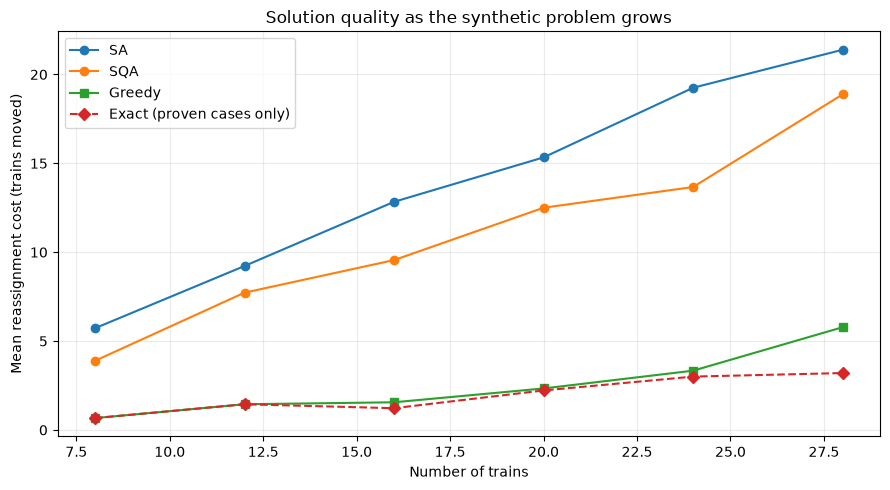

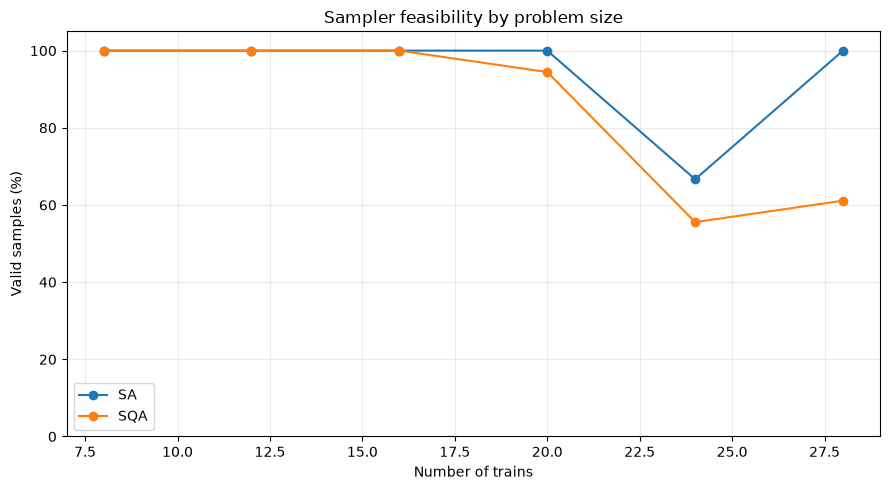

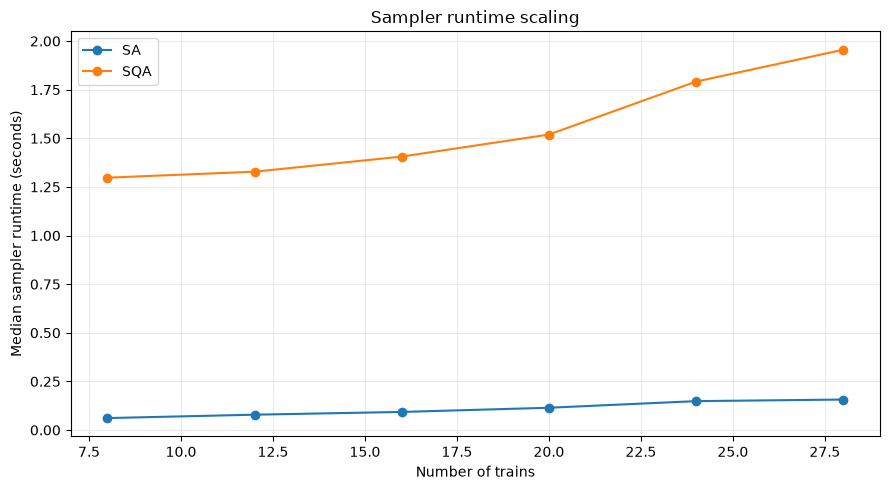

,n_trains,exact_status,dataset_count
0,8,OPTIMAL,9
1,12,OPTIMAL,9
2,16,OPTIMAL,9
3,20,OPTIMAL,9
4,24,INFEASIBLE,3
5,24,OPTIMAL,6
6,28,OPTIMAL,5
7,28,TIMEOUT,4


In [14]:
# Mean per-dataset run-best cost by train count and algorithm.
if not scaling_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    for alg in ["SA", "SQA"]:
        d = scaling_summary[scaling_summary.algorithm == alg].sort_values("n_trains")
        ax.plot(d.n_trains, d.mean_dataset_run_best_cost, marker="o", label=alg)
    # Greedy is one baseline result per dataset; overlay its size means.
    if not greedy_summary.empty:
        ax.plot(greedy_summary.n_trains, greedy_summary.mean_greedy_cost, marker="s", label="Greedy")
    exact_means = dataset_diagnostics[dataset_diagnostics.exact_status == "OPTIMAL"].groupby("n_trains").exact_optimum_cost.mean()
    if len(exact_means): ax.plot(exact_means.index, exact_means.values, marker="D", linestyle="--", label="Exact (proven cases only)")
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean reassignment cost (trains moved)")
    ax.set_title("Solution quality as the synthetic problem grows"); ax.grid(alpha=.25); ax.legend()
    plt.tight_layout(); plt.show()

if not scaling_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    for alg in ["SA", "SQA"]:
        d = scaling_summary[scaling_summary.algorithm == alg].sort_values("n_trains")
        ax.plot(d.n_trains, d.mean_feasibility_pct, marker="o", label=alg)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Valid samples (%)")
    ax.set_ylim(0, 105); ax.set_title("Sampler feasibility by problem size"); ax.grid(alpha=.25); ax.legend()
    plt.tight_layout(); plt.show()

if not scaling_summary.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    for alg in ["SA", "SQA"]:
        d = scaling_summary[scaling_summary.algorithm == alg].sort_values("n_trains")
        ax.plot(d.n_trains, d.median_runtime_s, marker="o", label=alg)
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Median sampler runtime (seconds)")
    ax.set_title("Sampler runtime scaling"); ax.grid(alpha=.25); ax.legend()
    plt.tight_layout(); plt.show()

if not exact_status_summary.empty:
    display(exact_status_summary)

## 14. Export reproducibility files

Keep the executed notebook together with these CSV and JSON files. The exports preserve the synthetic inputs, conflict graph, each solver run, exact statuses, capacity sensitivity and runtime settings.

In [15]:
def export_frame(frame, filename):
    if frame is None or frame.empty:
        print("Skipped empty:", filename); return
    frame.to_csv(filename, index=False)
    print("Saved", filename, "rows=", len(frame))

export_frame(dataset_diagnostics, "jaipur_v5_dataset_diagnostics.csv")
export_frame(generated_train_tables, "jaipur_v5_generated_train_tables.csv")
export_frame(conflict_edge_tables, "jaipur_v5_conflict_edges.csv")
export_frame(qubo_checks, "jaipur_v5_qubo_checks.csv")
export_frame(sampler_runs, "jaipur_v5_sampler_runs.csv")
export_frame(dataset_algorithm_summary, "jaipur_v5_dataset_algorithm_summary.csv")
export_frame(scaling_summary, "jaipur_v5_scaling_summary.csv")
export_frame(greedy_summary, "jaipur_v5_greedy_summary.csv")
export_frame(exact_status_summary, "jaipur_v5_exact_status_summary.csv")
export_frame(capacity_sensitivity_results, "jaipur_v5_capacity_sensitivity.csv")
export_frame(capacity_sensitivity_summary, "jaipur_v5_capacity_sensitivity_summary.csv")
export_frame(effort_sensitivity_results, "jaipur_v5_effort_sensitivity.csv")
export_frame(structural_overload_test, "jaipur_v5_structural_overload_test.csv")

metadata = {
    "notebook_version": "v5", "python_version": sys.version.split()[0],
    "platform": platform.platform(), "cpu": platform.processor(), "ram_gb": RAM_GB,
    "openjij_version": OPENJIJ_VERSION, "n_platforms": N_PLATFORMS,
    "clearance_min_assumption": BASE_CLEARANCE_MIN,
    "long_platform_count_main": LONG_PLATFORM_COUNT_MAIN,
    "long_train_coach_threshold": LONG_TRAIN_COACH_THRESHOLD,
    "train_counts": TRAIN_COUNTS, "delay_levels_min": DELAY_LEVELS_MIN,
    "dataset_seeds": DATASET_SEEDS, "solver_repeats": SOLVER_REPEATS,
    "num_reads": NUM_READS, "num_sweeps": NUM_SWEEPS,
    "exact_time_limit_s_per_dataset": EXACT_TIME_LIMIT_S,
    "greedy_restarts": GREEDY_RESTARTS,
    "run_main_benchmark": RUN_MAIN_BENCHMARK,
    "run_capacity_sensitivity": RUN_CAPACITY_SENSITIVITY,
    "run_effort_sensitivity": RUN_EFFORT_SENSITIVITY,
    "dataset_count": int(len(dataset_diagnostics)),
    "sampler_run_count": int(len(sampler_runs)),
    "qubo_all_dataset_checks_passed": bool(not qubo_checks.empty and qubo_checks.passed.all()),
    "synthetic_data_notice": "Train-level schedules, delays, nominal platform assignments and coach counts are synthetic; historical aggregate figures only inform calibration.",
    "quantum_notice": "OpenJij SQA is a classical simulation, not execution on quantum hardware."
}
with open("jaipur_v5_experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved jaipur_v5_experiment_metadata.json")

Saved jaipur_v5_dataset_diagnostics.csv rows= 54
Saved jaipur_v5_generated_train_tables.csv rows= 972
Saved jaipur_v5_conflict_edges.csv rows= 1383
Saved jaipur_v5_qubo_checks.csv rows= 54
Saved jaipur_v5_sampler_runs.csv rows= 216
Saved jaipur_v5_dataset_algorithm_summary.csv rows= 108
Saved jaipur_v5_scaling_summary.csv rows= 12
Saved jaipur_v5_greedy_summary.csv rows= 6
Saved jaipur_v5_exact_status_summary.csv rows= 8
Saved jaipur_v5_capacity_sensitivity.csv rows= 24
Saved jaipur_v5_capacity_sensitivity_summary.csv rows= 4
Saved jaipur_v5_effort_sensitivity.csv rows= 12
Saved jaipur_v5_structural_overload_test.csv rows= 2
Saved jaipur_v5_experiment_metadata.json


## 15. Interpretation checklist and V5 decision gate

Before writing a paper section from these results:

1. Confirm that all 54 dataset IDs are present and every QUBO identity check passed.
2. Keep `OPTIMAL`, `INFEASIBLE` and `TIMEOUT` separate. A timeout with an incumbent is not a proven optimum.
3. Compare SA/SQA optimality gaps only when Exact Search proved optimality.
4. A greedy failure is not proof of infeasibility. Report its feasible-solution rate separately.
5. Report the fraction of valid sampler reads as well as solution cost. A low-cost invalid bitstring is not a usable railway schedule.
6. Report average per-run best cost, best across repeats, runtime and exact-hit counts separately.
7. Compare four vs five long-platform capacity using the paired sensitivity export; only eligibility changes in that comparison.
8. Treat 30-minute maximum delay as a stress-test setting, not as a measured Jaipur delay distribution.
9. Do not claim SQA advantage unless results are repeatable across seeds and sizes, and compare its runtime cost against classical alternatives.
10. If Exact Search frequently times out at 24–28 trains, report that honestly and use its feasible incumbent only as an upper bound, not as a reference optimum.

**Next research decision:** use the results to determine whether the benchmark is difficult enough and whether SQA provides any measurable benefit over Greedy and SA. Do not change the objective or constraints merely to favour one algorithm.